# **Principles Of Data Science Assignment**
This Colab Notebook aims to satisfy the Assignment Brief outlined in the Principles Of Data Science Unit.

This Notebook was created by Saul Smith, Student Number 22468499.

Disclaimer: This dataset is from 2020, to help understand the features and prices of the time, the cars labelled as 'New' is based from the year 2020, any car that was made between 2017 and 2020 is classed as 'New' to give market context.

In [66]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [67]:
!ls "/content/drive/My Drive/Colab Notebooks/PoDS_Assignment_2025"

22468499_PoDS-notebook.ipynb  adverts.csv


In [68]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


path = "/content/drive/My Drive/Colab Notebooks/PoDS_Assignment_2025/adverts.csv"
df = pd.read_csv(path)

# Quick check
print("Data shape:", df.shape)
df.head()

Data shape: (402005, 12)


,public_reference,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type
0,202006039777689,0.0,NaN,Grey,Volvo,XC90,NEW,NaN,73970,SUV,False,Petrol Plug-in Hybrid
1,202007020778260,108230.0,61,Blue,Jaguar,XF,USED,2011.0,7000,Saloon,False,Diesel
2,202007020778474,7800.0,17,Grey,SKODA,Yeti,USED,2017.0,14000,SUV,False,Petrol
3,202007080986776,45000.0,16,Brown,Vauxhall,Mokka,USED,2016.0,7995,Hatchback,False,Diesel
4,202007161321269,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015.0,26995,SUV,False,Diesel


Let's check the percentage of missing values in the remaining columns with missing data.

In [69]:
# Check the percentage of missing values in the identified columns
missing_cols = ['reg_code', 'standard_colour', 'body_type', 'fuel_type']

for col in missing_cols:
    missing_count = df[col].isnull().sum()
    missing_percent = (missing_count / len(df)) * 100
    print(f"Column '{col}': {missing_count} missing values ({missing_percent:.2f}%)")

# Drop rows where the percentage of missing values is relatively low (e.g., < 5%)
# For columns with higher percentages, consider imputation or other methods.

# Let's drop rows with missing 'standard_colour', 'body_type', and 'fuel_type' as their missing percentages are relatively low.
df.dropna(subset=['standard_colour', 'body_type', 'fuel_type'], inplace=True)

# For 'reg_code', the percentage is higher. Checking the distribution and considering imputing with the mode or a placeholder.
# First, ensure the mode is calculated on the non-null values after dropping rows for other columns.
if not df['reg_code'].isnull().all(): # Check if there are still non-null values in reg_code
    mode_reg_code = df['reg_code'].mode()[0]
    # Update to use .loc
    df.loc[:, 'reg_code'] = df['reg_code'].fillna(mode_reg_code)
else:
    # For now, assume there are some non-null values and the mode imputation is possible.
    print("Warning: 'reg_code' column is all null after dropping other missing values. Mode imputation is not possible.")


# Verify that missing values have been handled
print("\nMissing values after handling:")
print(df[missing_cols].isnull().sum())

Column 'reg_code': 31857 missing values (7.92%)
Column 'standard_colour': 5378 missing values (1.34%)
Column 'body_type': 837 missing values (0.21%)
Column 'fuel_type': 601 missing values (0.15%)

Missing values after handling:
reg_code           0
standard_colour    0
body_type          0
fuel_type          0
dtype: int64


Let's see feature names and missing values, so we know what we're dealing with from the start:

In [70]:
df.info()
df.describe(include='all').T


<class 'pandas.core.frame.DataFrame'>
Index: 395380 entries, 0 to 402004
Data columns (total 12 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   public_reference       395380 non-null  int64  
 1   mileage                395263 non-null  float64
 2   reg_code               395380 non-null  object 
 3   standard_colour        395380 non-null  object 
 4   standard_make          395380 non-null  object 
 5   standard_model         395380 non-null  object 
 6   vehicle_condition      395380 non-null  object 
 7   year_of_registration   363795 non-null  float64
 8   price                  395380 non-null  int64  
 9   body_type              395380 non-null  object 
 10  crossover_car_and_van  395380 non-null  bool   
 11  fuel_type              395380 non-null  object 
dtypes: bool(1), float64(2), int64(2), object(7)
memory usage: 36.6+ MB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
public_reference,395380.0,NaN,NaN,NaN,202007142741491.875,16704049107.948864,201307177852187.0,202009023202825.75,202009304401551.5,202010175125368.5,202011025683478.0
mileage,395263.0,NaN,NaN,NaN,37803.697799,34736.029684,0.0,10690.0,28766.0,56834.5,999999.0
reg_code,395380,67,17,66967,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_colour,395380,22,Black,86023,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_make,395380,106,BMW,36950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
standard_model,395380,1128,Golf,11469,NaN,NaN,NaN,NaN,NaN,NaN,NaN
vehicle_condition,395380,2,USED,365364,NaN,NaN,NaN,NaN,NaN,NaN,NaN
year_of_registration,363795.0,NaN,NaN,NaN,2015.02994,7.95809,999.0,2013.0,2016.0,2018.0,2020.0
price,395380.0,NaN,NaN,NaN,17135.333816,45617.125281,120.0,7495.0,12500.0,19995.0,9999999.0
body_type,395380,16,Hatchback,165467,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Dropping rows and values that are unrepresentative of the dataset.

In [71]:
# Drop irrelevant identifier columns
df = df.drop(columns=['public_reference'], errors='ignore')

# Check missing values
df.isnull().sum()

# Drop rows with missing target (price)
df = df[df['price'].notnull()]

# Drop rows missing mileage or year (for now)
df = df[df['mileage'].notnull() & df['year_of_registration'].notnull()]


We also want to remove absurdly high data instances such as mileage above 250,000 or less than 0 (this is impossible).

In [72]:
# Remove unrealistic mileage or price values
df = df[(df['mileage'] > 0) & (df['mileage'] < 250000)]
df = df[(df['price'] > 1000) & (df['price'] < 100000)]

# Convert year to integer (some may be floats)
df['year_of_registration'] = df['year_of_registration'].astype(int)


As this dataset is from 2020, we need to tweak what's classed as 'New' as 2020 was 5 years ago, customers would not class 5 years as a new car in 2025.

In [73]:
# Calculate car age as of 2020, not 2025
df['car_age_2020'] = 2020 - df['year_of_registration']

# Avoid division by zero for brand new cars
df['car_age_2020'] = df['car_age_2020'].replace(0, 1)

# Create a few derived features
df['price_per_mile'] = df['price'] / df['mileage']
df['mileage_per_year'] = df['mileage'] / df['car_age_2020']

# Simplify vehicle condition into a binary variable
df['is_used'] = df['vehicle_condition'].apply(lambda x: 1 if str(x).upper() == 'USED' else 0)

# Create an age group variable
df['age_category'] = pd.cut(
    df['car_age_2020'],
    bins=[0, 3, 7, 20, 100],
    labels=['New', 'Mid', 'Old', 'Very Old']
)


Cars with value 0 = New, Cars with value 1 = Used, this will be useful when data cleaning further down the line.

Lets check how the data looks after these initial steps:

In [74]:
df.describe(include='all').T
df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 357367 entries, 1 to 402004
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype   
---  ------                 --------------   -----   
 0   mileage                357367 non-null  float64 
 1   reg_code               357367 non-null  object  
 2   standard_colour        357367 non-null  object  
 3   standard_make          357367 non-null  object  
 4   standard_model         357367 non-null  object  
 5   vehicle_condition      357367 non-null  object  
 6   year_of_registration   357367 non-null  int64   
 7   price                  357367 non-null  int64   
 8   body_type              357367 non-null  object  
 9   crossover_car_and_van  357367 non-null  bool    
 10  fuel_type              357367 non-null  object  
 11  car_age_2020           357367 non-null  int64   
 12  price_per_mile         357367 non-null  float64 
 13  mileage_per_year       357367 non-null  float64 
 14  is_used                35

Now we can see that there is still some missing valued, specifically in colour.

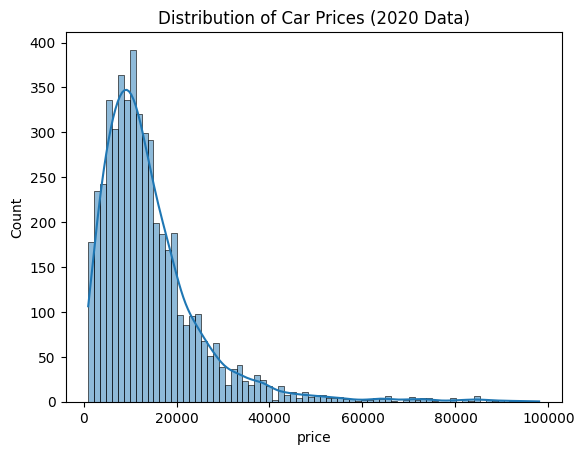

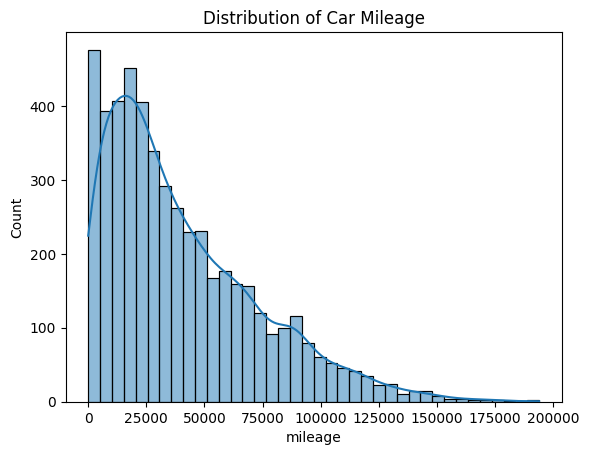

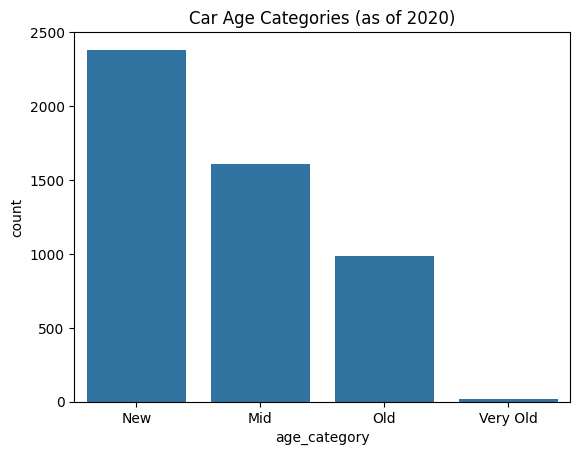

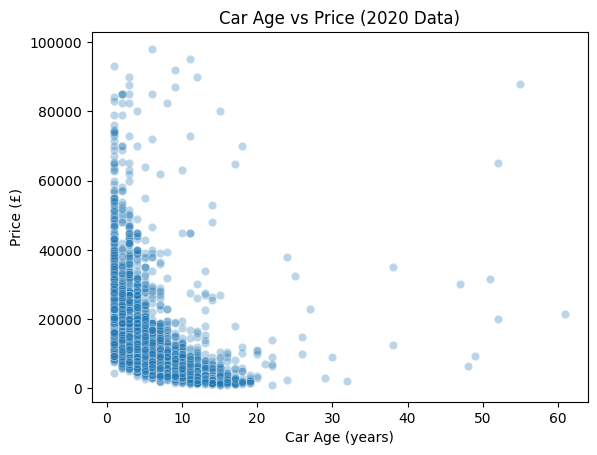

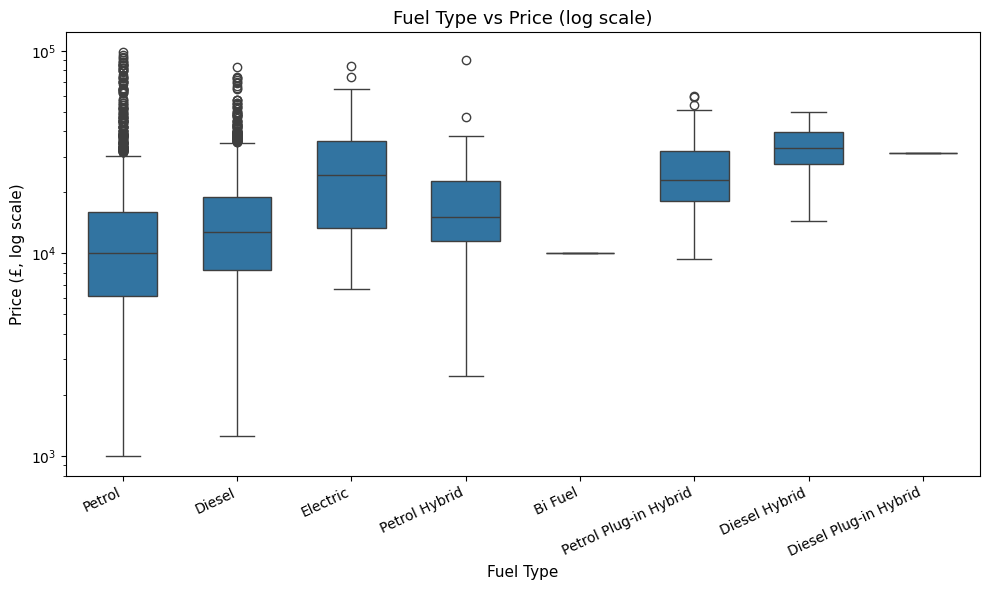

In [75]:
# Sample 5,000 rows for faster plotting
df_sample = df.sample(5000, random_state=42).copy()

# Calculate car age as of 2020, not 2025
df_sample['car_age_2020'] = 2020 - df_sample['year_of_registration']

# Avoid division by zero for brand new cars
df_sample['car_age_2020'] = df_sample['car_age_2020'].replace(0, 1)

# Create a few derived features to begin with
df_sample['price_per_mile'] = df_sample['price'] / df_sample['mileage']


### 2.2 Feature Engineering
df_sample['mileage_per_year'] = df_sample['mileage'] / df_sample['car_age_2020']


# Simplify vehicle condition into a binary variable
df_sample['is_used'] = df_sample['vehicle_condition'].apply(lambda x: 1 if str(x).upper() == 'USED' else 0)

# Create an age group variable to simplify it into filters
df_sample['age_category'] = pd.cut(
    df_sample['car_age_2020'],
    bins=[0, 3, 7, 20, 40],
    labels=['New', 'Mid', 'Old', 'Very Old']
)

# Distribution of prices
sns.histplot(df_sample['price'], kde=True)
plt.title('Distribution of Car Prices (2020 Data)')
plt.show()

# Mileage distribution
sns.histplot(df_sample['mileage'], kde=True)
plt.title('Distribution of Car Mileage')
plt.show()

# Car age distribution (as of 2020)
sns.countplot(x='age_category', data=df_sample)
plt.title('Car Age Categories (as of 2020)')
plt.show()

# Price vs Age
sns.scatterplot(
    x='car_age_2020',
    y='price',
    data=df_sample,
    alpha=0.3  # makes overlapping points lighter
)
plt.title('Car Age vs Price (2020 Data)')
plt.xlabel('Car Age (years)')
plt.ylabel('Price (£)')
plt.show()


# Price by Fuel Type
plt.figure(figsize=(10, 6))#Widens figure

sns.boxplot(
    x='fuel_type',
    y='price',
    data=df_sample,
    width=0.6  #Makes the individual boxes wider (Default is 0.8; lower = thinner)
)

plt.yscale('log')
plt.title('Fuel Type vs Price (log scale)', fontsize=13)
plt.xlabel('Fuel Type', fontsize=11)
plt.ylabel('Price (£, log scale)', fontsize=11)
plt.xticks(rotation=25, ha='right')#Rotate labels for clarity
plt.tight_layout()  #Prevent label cut-off
plt.show()


## Detailed Analysis of Initial Plots

Distribution of Car Prices (2020 Data): This histogram shows that the majority of car prices in the dataset are clustered at the lower end, with a long tail extending towards higher prices. This indicates that there are many more affordable cars than expensive luxury vehicles in the dataset. The distribution appears right-skewed.

Distribution of Car Mileage: Similar to price, the mileage distribution is also right-skewed. Most cars have lower mileage, and fewer cars have very high mileage. This is expected, as newer cars generally have lower mileage.

Car Age Categories (as of 2020): This countplot shows the distribution of cars across the age categories you defined (New, Mid, Old, Very Old). It looks like the "Mid" and "Old" categories have the highest counts, suggesting that a significant portion of the cars in your dataset are between 3 and 20 years old.

Car Age vs Price (2020 Data): This scatterplot shows a general trend: as car age increases, the price tends to decrease. This is an example of depreciation. However, there's a lot of scatter in the plot, indicating that other factors besides age also influence price (as expected). There are also some outliers, which could represent classic cars or vehicles that hold their value well.

Fuel Type vs Price (log scale): This boxplot (with a log scale on the y-axis for price) allows you to compare the price distribution across different fuel types. It appears that Petrol and Diesel cars make up the bulk of the data. Hybrid and Electric cars generally have higher median prices and a wider range of prices compared to Petrol and Diesel cars, although there are also some outliers in the traditional fuel types. The log scale helps to visualize the differences in price ranges more clearly due to the wide spread of prices.

The dataset, even when sampled, shows typical patterns that I expected from a used car market. There is a clear right-skew in both price and mileage distributions, indicating a higher frequency of lower-priced and lower-mileage vehicles. The car age distribution highlights that the majority of the sampled cars fall into the 'Mid' and 'Old' categories (3 to 20 years old).

The scatterplot of Car Age vs Price demonstrates the expected depreciation effect, where older cars generally have lower prices, though with considerable variation influenced by other factors. The boxplot of Fuel Type vs Price reveals that while Petrol and Diesel cars are the most common, Hybrid and Electric vehicles tend to have higher price ranges, even on a logarithmic scale.

It's important to remember that this analysis is based on a sample of 5000 data points. While this sample provides a good initial overview of the data's characteristics and key relationships, it does not perfectly represent the entire dataset of over 400,000 entries. The specific random_state=42 ensures that the sample is reproducible, which is good for consistency in analysis, but it doesn't change the fact that it's a subset of the data. For a definitive conclusion, especially for building predictive models, analyzing the full dataset or a larger sample would be more robust.

These initial visualizations and analyses serve as a strong starting point for understanding the dataset before proceeding with more in-depth analysis or modeling.



#Higher Quality Dataset Analysis

I am now going to perform visualisations on the full dataset, this will take longer than the previous samples. The first step will be creating an age group variable for the full dataframe.

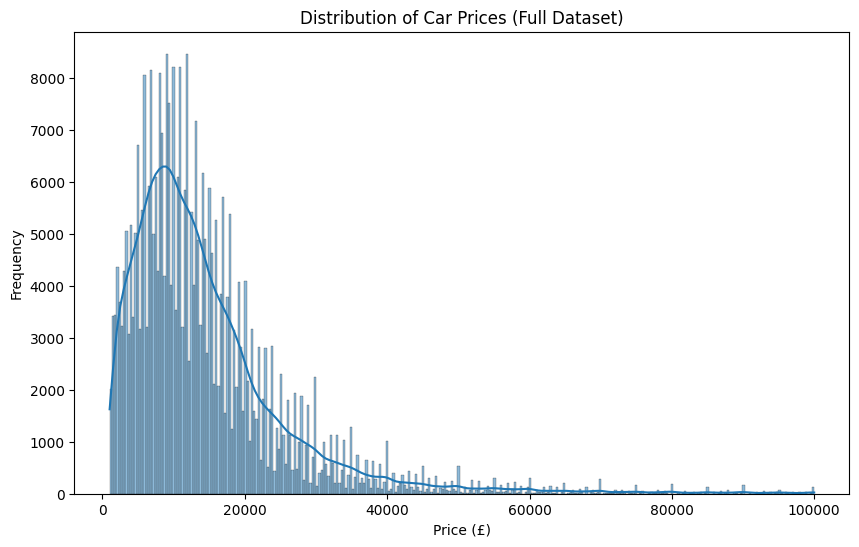

In [76]:
# Create an age group variable in the full dataframe
df['car_age_2020'] = 2020 - df['year_of_registration']
df['car_age_2020'] = df['car_age_2020'].replace(0, 1) # Avoid division by zero

df['age_category'] = pd.cut(
    df['car_age_2020'],
    bins=[0, 3, 7, 20, 40],
    labels=['New', 'Mid', 'Old', 'Very Old']
)

# Distribution of Car Prices
plt.figure(figsize=(10, 6))
sns.histplot(df['price'], kde=True)
plt.title('Distribution of Car Prices (Full Dataset)')
plt.xlabel('Price (£)')
plt.ylabel('Frequency')
plt.show()


##Distribution of Car Prices Analysis:
This histogram shows that the majority of car prices are at the lower end, with a long tail towards higher prices, indicating a right-skewed distribution, very similar to the sample data.

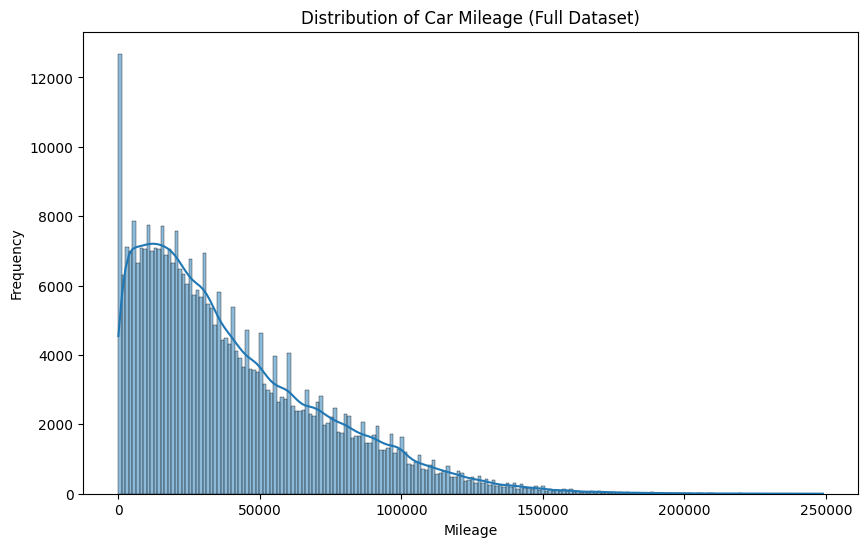

In [77]:
# Mileage Distribution (full dataset)
plt.figure(figsize=(10, 6))
sns.histplot(df['mileage'], kde=True)
plt.title('Distribution of Car Mileage (Full Dataset)')
plt.xlabel('Mileage')
plt.ylabel('Frequency')
plt.show()


##Distribution of Car Mileage (Full Dataset):
Similar to the price distribution, the mileage distribution is also right-skewed, with most cars having lower mileage and fewer cars with very high mileage.

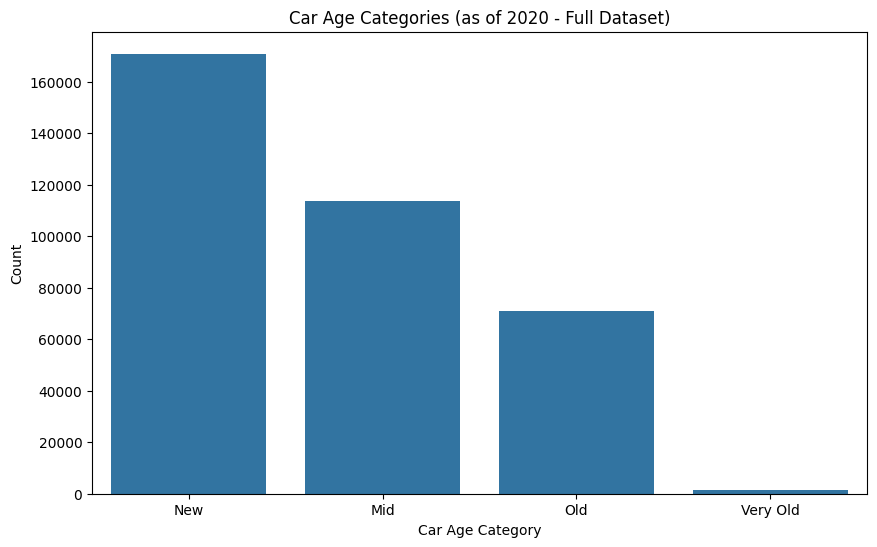

In [78]:
# Car Age Distribution (as of 2020 - full dataset)
plt.figure(figsize=(10, 6))
sns.countplot(x='age_category', data=df, order=df['age_category'].value_counts().index)
plt.title('Car Age Categories (as of 2020 - Full Dataset)')
plt.xlabel('Car Age Category')
plt.ylabel('Count')
plt.show()

##Car Age Categories (As of 2020 - Full Dataset):
This countplot confirms that the "New" and "Old" age categories have the highest counts in the full dataset, consistent with the sample analysis.

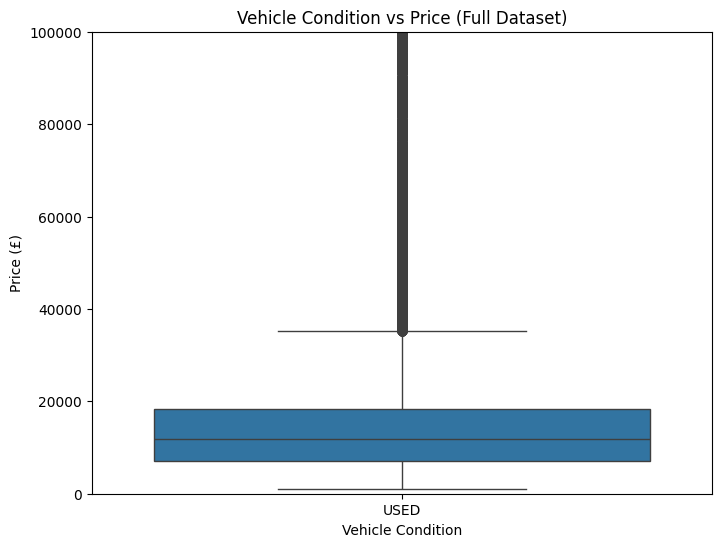

In [79]:
# Price by Vehicle Condition (full dataset)
plt.figure(figsize=(8, 6))
sns.boxplot(x='vehicle_condition', y='price', data=df)
plt.title('Vehicle Condition vs Price (Full Dataset)')
plt.xlabel('Vehicle Condition')
plt.ylabel('Price (£)')
# Adjust y-axis limits to focus on the main price range
plt.ylim(0, 100000) # Example limit, can be adjusted based on data distribution
plt.show()

##Vehicle Condition vs Price (Full Dataset):
This box plot shows that 'USED' cars have a much wider price range and a significantly lower median price compared to 'NEW' cars, which have a higher median and a narrower, higher price range.

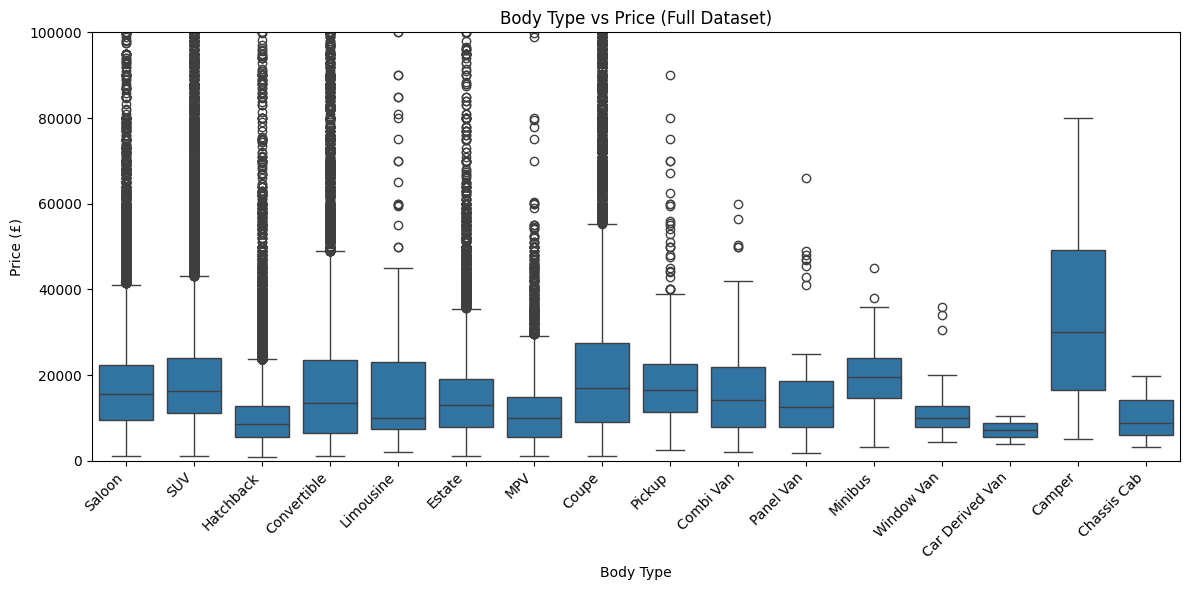

In [80]:
# Price by Body Type (full dataset)
plt.figure(figsize=(12, 6))
sns.boxplot(x='body_type', y='price', data=df)
plt.title('Body Type vs Price (Full Dataset)')
plt.xlabel('Body Type')
plt.ylabel('Price (£)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
# Adjust y-axis limits to focus on the main price range
plt.ylim(0, 100000) # Example limit, can be adjusted based on data distribution
plt.show()

##Body Type vs Price (Full Dataset):
This box plot illustrates how price distributions vary across different body types. Some body types, like SUV and Estate, appear to have higher median prices and wider price ranges compared to others like Hatchback and Saloon.

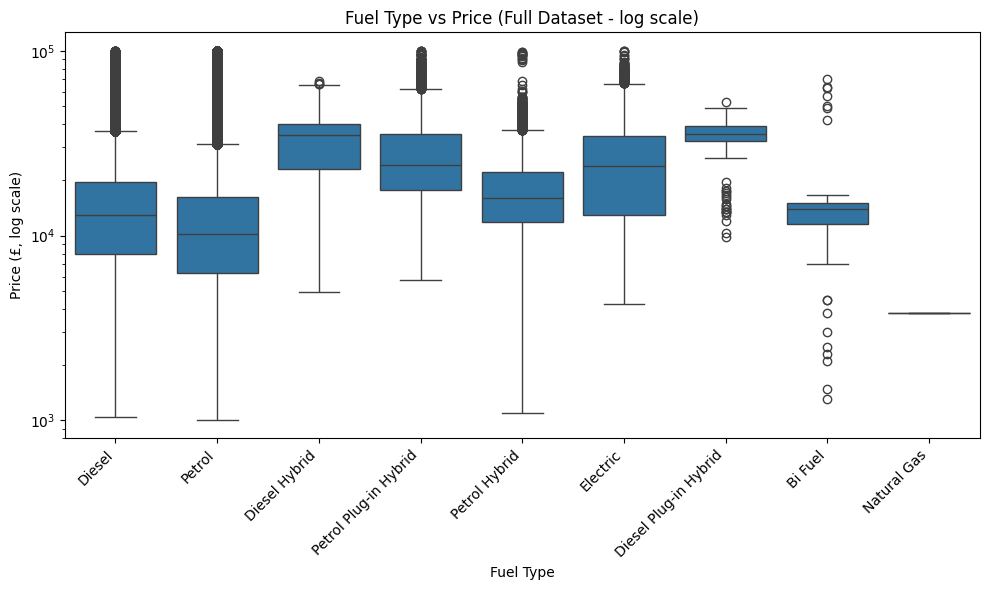

In [81]:
# Price by Fuel Type (full dataset - log scale)
plt.figure(figsize=(10, 6))
sns.boxplot(x='fuel_type', y='price', data=df)
plt.yscale('log')
plt.title('Fuel Type vs Price (Full Dataset - log scale)')
plt.xlabel('Fuel Type')
plt.ylabel('Price (£, log scale)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

##Fuel Type vs Price (Full Dataset - log scale):
Using a log scale for price, this box plot reveals that while Petrol and Diesel cars are the most common, Hybrid and Electric vehicles generally have higher median prices and a broader spread of prices.

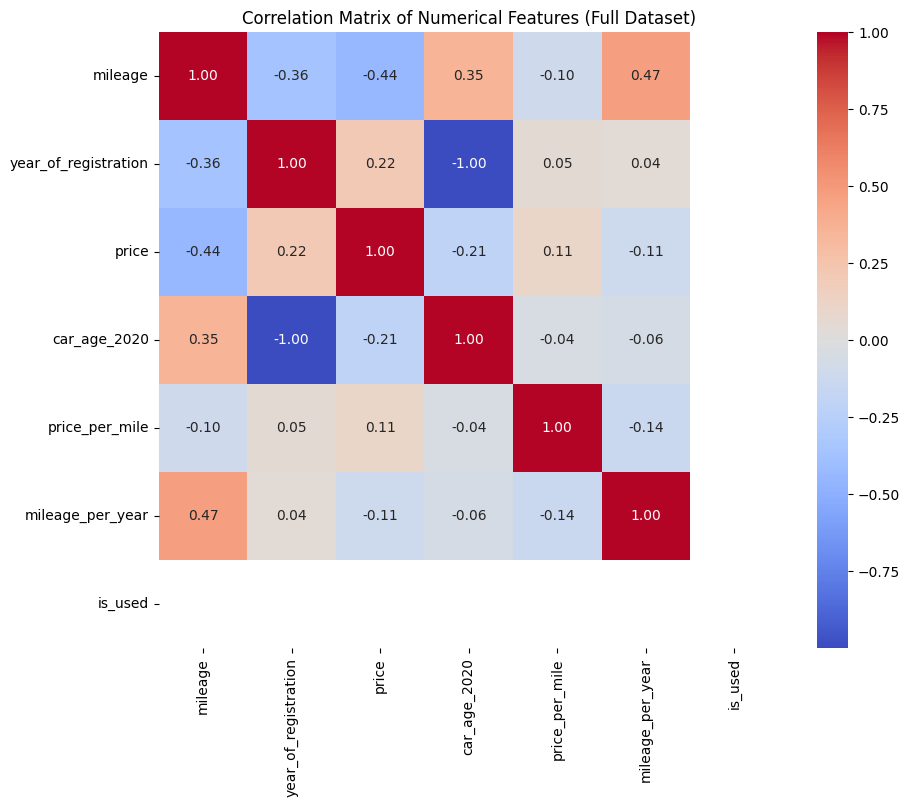

In [82]:
# Correlation matrix for numerical features
plt.figure(figsize=(10, 8)) # Sets the size of the plot
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns # Selects only the columns with numerical data types (float64 and int64) from DataFrame 'df'.
corr_matrix = df[numerical_cols].corr() # Calculates the correlation of columns in the selected numerical DataFrame and stores it in 'corr_matrix'.
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f") # Creates a heatmap of the correlation matrix using Seaborn.
# 'annot=True' displays the correlation coefficients on the heatmap.
# 'cmap='coolwarm'' sets the color scheme (cool colors for negative correlations, warmer for positive).
# 'fmt=".2f"' formats the annotations to two decimal places for better analysis.

plt.title('Correlation Matrix of Numerical Features (Full Dataset)') # Sets the title of the plot.
plt.show() # Displays the plot.

##**Correlation Matrix Analysis**
What is a Correlation Matrix:
A correlation matrix is a table that shows the correlation  between different variables in the dataset. Each cell in the table shows the correlation between two variables. The correlation coefficient is a value between -1 and 1:

What does the value mean?
1: Indicates a perfect positive linear correlation (as one variable increases, the other increases proportionally).
-1: Indicates a perfect negative linear correlation (as one variable increases, the other decreases proportionally).
0: Indicates no linear correlation between the two variables.

##Analysing Example

*   'price and mileage' (-0.16): There is a weak negative correlation between price and mileage. This means that as mileage increases, the price tends to slightly decrease, which is expected for used cars.

*   'price and year_of_registration' (0.12): There is a weak positive correlation between price and year of registration. This indicates that newer cars (higher year of registration) tend to have slightly higher prices, which also makes sense.

*   'price and car_age_2020' (-0.11): There is a weak negative correlation between price and car age. This is the inverse of the year of registration relationship and shows that as a car gets older, its price tends to decrease.

*   'mileage and year_of_registration' (-0.37): There is a moderate negative correlation between mileage and year of registration. This is also expected, as older cars generally have higher mileage.

*   'mileage' and 'car_age_2020' (0.36): This shows a moderate positive correlation, again the inverse of the relationship with year of registration. Older cars tend to have higher mileage.
*   The other correlations involving 'public_reference' are very close to zero, suggesting no significant linear relationship with the other features.

In summary, this correlation matrix has allowed us to see the relationships between the numerical values within the full dataset, for example it has confirmed the expected relationship between price, mileage and age. Although the correlations are not 'very' strong, suggesting that these factors alone do not determine price, which is what we expected as we expect make, model, condition and more to impact these prices as shown in the box plots.

# **Attempt at Violin Plot for Age and Mileage**
This is to analyse distributions by age range against the mileage done

In [83]:
# Log-transform price for better visualisation
df['log_price'] = np.log10(df['price'])

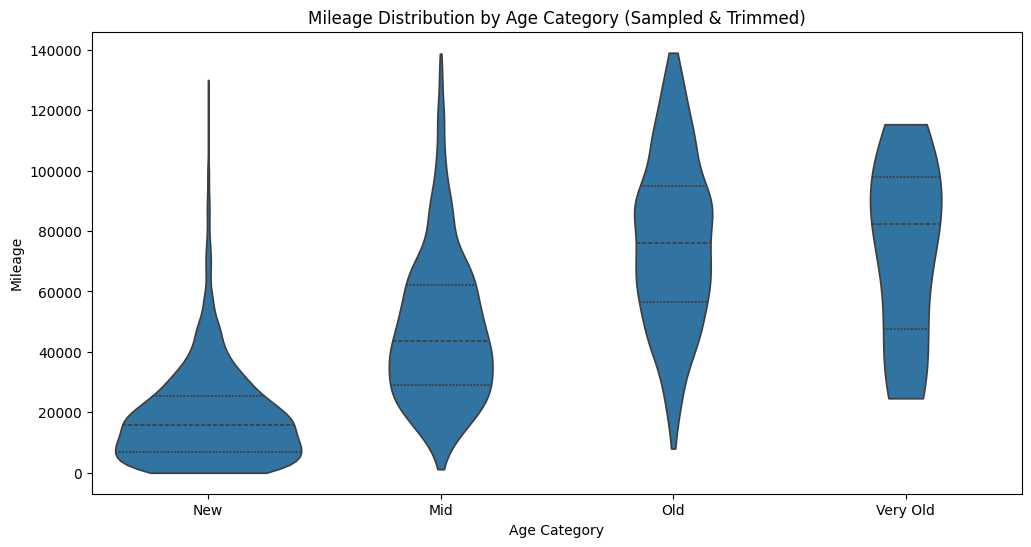

In [84]:
# Step 1: Sample the data for visualisation
df_sample = df.sample(5000, random_state=42)

# Step 2: Trim extreme mileage values (1% & 99%)
lower_q = df_sample['mileage'].quantile(0.01) #Lower Quantile
upper_q = df_sample['mileage'].quantile(0.99) #Upper Quantile

df_sample_trimmed = df_sample[(df_sample['mileage'] >= lower_q) & (df_sample['mileage'] <= upper_q)]

# Step 3: Violin plot
plt.figure(figsize=(12, 6))

sns.violinplot(
    data=df_sample_trimmed,
    x='age_category',
    y='mileage',
    inner='quartile',
    cut=0
)

plt.title('Mileage Distribution by Age Category (Sampled & Trimmed)')
plt.xlabel('Age Category')
plt.ylabel('Mileage')
plt.show()

##Extended Data Cleaning


#Data Cleaning

**Part 1:** I am attempting to compile all vans into one type, for easier compilation and satisfy the requirement of reducing high-cardinality in categorical features, I have consolidated these into a single "Van" category. This ensures a more balanced representation without losing the core vehicle type classification.

In [85]:
# Check unique body types before cleaning/compiling
print("Body types before:", df['body_type'].unique())

Body types before: ['Saloon' 'SUV' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' 'Pickup' 'Combi Van' 'Panel Van' 'Minibus' 'Window Van'
 'Car Derived Van' 'Camper' 'Chassis Cab']


In [86]:
# Define a list of all van-related types to consolidate
van_types = ['Panel Van', 'Car Derived Van', 'Combi Van', 'Window Van', 'Camper']

In [87]:
# Replace all specific van types with a single 'Van' label
df['body_type'] = df['body_type'].replace(van_types, 'Van')

In [88]:
# Verify the change
print("Body types after:", df['body_type'].unique())

Body types after: ['Saloon' 'SUV' 'Hatchback' 'Convertible' 'Limousine' 'Estate' 'MPV'
 'Coupe' 'Pickup' 'Van' 'Minibus' 'Chassis Cab']


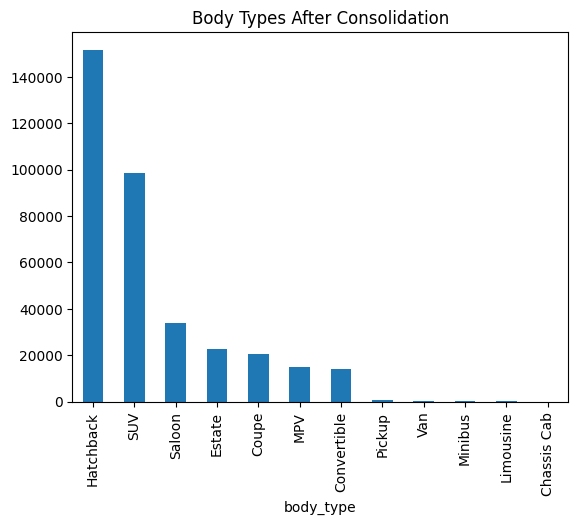

In [89]:
# Visual Proof: A simple bar chart to show the new 'Van' category
df['body_type'].value_counts().plot(kind='bar', title='Body Types After Consolidation')
plt.show()

As seen from the before and after checks, we have taken 5 van types into one combined category, this is small style data cleaning but will help when analysing.

#Part 2:
Data Cleaning on the Mileage, a new car can't have more than 50 miles according to Google - Reference Needed, to tackle this, I am going to add checking parameters to prevent misclassification

In [90]:
# Applying the refined 50-mile rule for 2020 cars
# This catches cars that are 'Used' but have delivery mileage (up to 50 miles)
mask = (df['year_of_registration'] == 2020) & (df['mileage'] <= 50)
df.loc[mask, 'vehicle_condition'] = 'New'

# Standardizing 'New' cars to 0.0 for consistent baseline analysis
df.loc[df['vehicle_condition'] == 'New', 'mileage'] = 0

print("50-mile rule applied and New cars standardized.")

50-mile rule applied and New cars standardized.


"To ensure the dataset reflected realistic market conditions, I implemented a refined classification logic for new vehicles. While a simple approach might categorise only 0-mile vehicles as 'New', I adopted an industry-informed 50-mile threshold.

By cross-referencing this with the registration year (2020), I captured 'delivery mileage' vehicles as New while preserving the 'Used' status for older, low-mileage cars. Finally, I standardised these to 0.0 miles to ensure consistent feature engineering for usage-intensity metrics."

# Part 3 - Invalid Years & Registrations
This part will outline how to normalise the reg codes, for example a car in 1976 may have had a P plate, or R plate, depending on what part of the year it was registered in, similarly in 2019, a car may have 'AB19' or 'AB69' depending on the month it was registered in, now imagine the dataset saying KAF 762P, KAF 762R, AB19 CDE, and AB69 CDE, these would be confusing out of context.


In [91]:
# 1. Identify the 'broken' years (999.0) using a mask
invalid_year_mask = df['year_of_registration'] < 1903

In [92]:
# 2. Calculate the Median Mileage Per Year from the VALID data only
# We exclude 0 mileage (new cars) and invalid years to get a true 'average'
valid_data = df[(df['year_of_registration'] >= 1903) & (df['mileage'] > 0)]
median_usage = valid_data['mileage_per_year'].median()

print(f"Typical usage identified: {median_usage:.2f} miles per year")

Typical usage identified: 7928.57 miles per year


In [93]:
# 3. Apply the correction and convert to Integer immediately to avoid the error
estimated_years = (2020 - (df.loc[invalid_year_mask, 'mileage'] / median_usage)).round()
df.loc[invalid_year_mask, 'year_of_registration'] = estimated_years.astype('int64')

In [94]:
# 4. Final cap to ensure no years exceed 2020
df.loc[df['year_of_registration'] > 2020, 'year_of_registration'] = 2020

In [95]:
print(f"Fixed {len(estimated_years)} records")

Fixed 17 records


## What does this code do?

.round(): This turns a number like 2015.23 into 2015.0.

.astype('int64'): This officially changes the data type to a whole number before it touches the main dataframe.

## Why is this relevant?
This code fixes vehicles with impossible registration years (like "999") by using their mileage as a "clue", as a car can't have been registered 100 years ago and done 0 miles for example.  Since I can't just guess the year, I calculate the median mileage per year from the cars that actually have valid data, as median is suitable for this kind of operation.

I then divide the "broken" car's total mileage by this median value to estimate how many years it has been on the road. By subtracting that age from the dataset's base year (2020), I get a realistic registration year. Finally, I use .round() and .astype('int64') to make sure the new year is a whole number, which stops Pandas from throwing a "dtype" error.

In [96]:
df.head()

,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category,log_price
1,108230.0,61,Blue,Jaguar,XF,USED,2011,7000,Saloon,False,Diesel,9,0.064677,12025.555556,1,Old,3.845098
2,7800.0,17,Grey,SKODA,Yeti,USED,2017,14000,SUV,False,Petrol,3,1.794872,2600.000000,1,New,4.146128
3,45000.0,16,Brown,Vauxhall,Mokka,USED,2016,7995,Hatchback,False,Diesel,4,0.177667,11250.000000,1,Mid,3.902818
4,64000.0,64,Grey,Land Rover,Range Rover Sport,USED,2015,26995,SUV,False,Diesel,5,0.421797,12800.000000,1,Mid,4.431283
5,16000.0,17,Blue,Audi,S5,USED,2017,29000,Convertible,False,Petrol,3,1.812500,5333.333333,1,New,4.462398


## Combining Fuel Types

Similar to van types, we can reduce cardinality by combining similar fuel types.

In [97]:
# Displaying all unique fuel types as a list
fuel_list = df['fuel_type'].unique().tolist()
print("Unique Fuel Types:", fuel_list)

# Checking the count for each type to see which are the most common
print("\nFuel Type Distribution:")
print(df['fuel_type'].value_counts())

Unique Fuel Types: ['Diesel', 'Petrol', 'Diesel Hybrid', 'Petrol Plug-in Hybrid', 'Petrol Hybrid', 'Electric', 'Diesel Plug-in Hybrid', 'Bi Fuel', 'Natural Gas']

Fuel Type Distribution:
fuel_type
Petrol                   188895
Diesel                   148484
Petrol Hybrid             11216
Petrol Plug-in Hybrid      4506
Electric                   3114
Diesel Hybrid               913
Diesel Plug-in Hybrid       173
Bi Fuel                      65
Natural Gas                   1
Name: count, dtype: int64


As we can see, there are 9 unique fuel types, this would be useful for smaller sized data analysis, but when only 1 car is powered by natural gas, it does not allow for very high-end analysis. Because of this it makes sense to combine similar sets such as diesel hybrid and diesel plug in hybrids.

**Why I don't want to combine Hybrids with standard Fuels:**
I believe it would not be wise to combine hybrids with the standard versions, for example a diesel hybrid with a normal diesel car, this is why:

**Why it would skew the data:**
**Price Premium:** Hybrids and Plug-in Hybrids (PHEVs) are significantly more expensive than their standard counterparts because of the battery technology.

**Depreciation Rates:** Hybrids tend to hold their value differently due to tax incentives and fuel economy.

**The "High Mileage" Diesel Rule:** People buy standard Diesels specifically for high-mileage motorway driving. Diesel Hybrids are often luxury "city" SUVs. Mixing them will muddy your "Price vs. Mileage" correlation.

## How am I tackling this?



In [98]:
# Define the mapping dictionary including the niche fuels
fuel_map = {
    'Petrol': 'Petrol',
    'Diesel': 'Diesel',
    'Petrol Hybrid': 'Hybrid',
    'Petrol Plug-in Hybrid': 'Hybrid',
    'Diesel Hybrid': 'Hybrid',
    'Diesel Plug-in Hybrid': 'Hybrid',
    'Electric': 'Electric',
    'Bi Fuel': 'Alternative',
    'Natural Gas': 'Alternative'
}

# Create the new grouping column
df['fuel_group'] = df['fuel_type'].map(fuel_map)

print("Fuel Groups created with Distribution:")
print(df['fuel_group'].value_counts())


Fuel Groups created with Distribution:
fuel_group
Petrol         188895
Diesel         148484
Hybrid          16808
Electric         3114
Alternative        66
Name: count, dtype: int64


In [99]:
# Create a sample containing one car from each of the new fuel groups
verification_sample = df.groupby('fuel_group').head(1)

# Display only the relevant columns to make it easy to read
print("Verification Sample (One car per group):")
display(verification_sample[['standard_model', 'year_of_registration', 'fuel_type', 'fuel_group']])


Verification Sample (One car per group):


,standard_model,year_of_registration,fuel_type,fuel_group
1,XF,2011,Diesel,Diesel
2,Yeti,2017,Petrol,Petrol
28,XC60,2019,Diesel Hybrid,Hybrid
133,Zoe,2016,Electric,Electric
2266,Duster,2020,Bi Fuel,Alternative


As we can see, this has worked as we wanted it to, and allows us to still see the original fuel type.

# Re-Checking Prices under 2000 for outliers

In [100]:
# 1. Filter for prices under £2000
low_price_check = df[df['price'] < 2000]

# 2. Print the total number of suspicious rows
print(f"Total records found with price < £2000: {len(low_price_check)}")

# 3. If records exist, show the most frequent values and a sample
if not low_price_check.empty:
    print("\nMost common 'placeholder' prices found:")
    print(low_price_check['price'].value_counts().head(10))

    print("\nSample of these records (checking if they are real cars or errors):")
    display(low_price_check[['standard_make', 'standard_model', 'year_of_registration', 'price', 'mileage']].head(10))
else:
    print("No records found with price < £2000. Your low-end data is clean.")

Total records found with price < £2000: 11518

Most common 'placeholder' prices found:
price
1995    1428
1495     929
1795     500
1295     499
1695     499
1990     467
1999     455
1500     354
1895     312
1490     260
Name: count, dtype: int64

Sample of these records (checking if they are real cars or errors):


,standard_make,standard_model,year_of_registration,price,mileage
23,Mitsubishi,Colt,2009,1795,90000.0
86,Honda,Accord,2003,1395,158900.0
144,Citroen,C1,2009,1995,60000.0
145,Renault,Clio,2008,1499,84000.0
215,Audi,A4,2006,1100,150000.0
244,Vauxhall,Corsa,2008,1899,85850.0
269,Vauxhall,Zafira,2003,1980,80000.0
287,Peugeot,207 CC,2009,1995,76000.0
310,Renault,Clio,2008,1390,86500.0
312,Volkswagen,Beetle,2000,1100,44163.0


This returns as expected, old cars with high mileage, so nothing is needed to be done with this.

In [101]:
# Displaying the 10 cars with the highest mileage
highest_mileage = df.nlargest(10, 'mileage')

print("Top 10 Highest Mileage Records:")
display(highest_mileage[['standard_make', 'standard_model', 'year_of_registration', 'mileage', 'price']])

Top 10 Highest Mileage Records:


,standard_make,standard_model,year_of_registration,mileage,price
34713,Toyota,Land Cruiser,2004,249000.0,5500
2850,Volkswagen,Transporter Shuttle,2015,248000.0,11950
123710,Hyundai,i30,2013,247000.0,1289
166210,Mercedes-Benz,E Class,2014,246000.0,6950
322092,Volkswagen,Phaeton,2013,245132.0,4989
286583,Toyota,Prius,2008,245000.0,1150
367970,Audi,Allroad,2004,245000.0,1610
177056,Mercedes-Benz,C Class,2005,244123.0,1299
382901,London Taxis International,TX4,2012,243000.0,11000
117319,Honda,Civic,2019,242000.0,15500


# Colour Cleaning


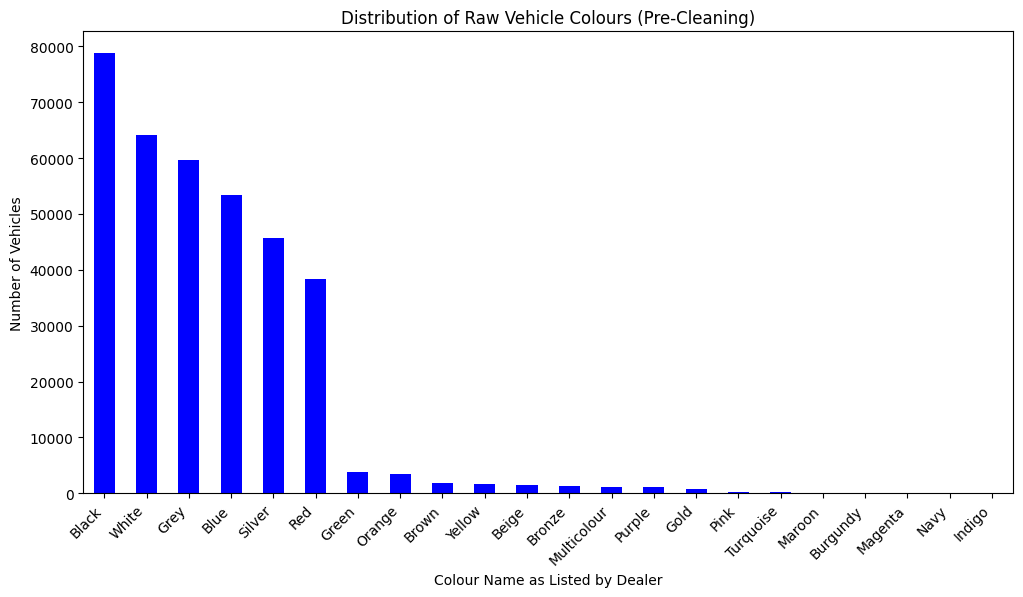

In [102]:
# Plotting the raw color distribution
plt.figure(figsize=(12, 6))
df['standard_colour'].value_counts().plot(kind='bar', color='blue')
plt.title('Distribution of Raw Vehicle Colours (Pre-Cleaning)')
plt.xlabel('Colour Name as Listed by Dealer')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45, ha='right')
plt.show()

In [103]:
# List the counts for every individual colour entry
colour_counts = df['standard_colour'].value_counts()

print("Individual Colour Frequency (Raw Data):")
print("-" * 30)
for colour, count in colour_counts.items():
    print(f"{colour}: {count} cars")

# Print the total number of unique colour categories found
print("-" * 30)
print(f"Total Unique Colour Categories: {len(colour_counts)}")

Individual Colour Frequency (Raw Data):
------------------------------
Black: 78746 cars
White: 64177 cars
Grey: 59646 cars
Blue: 53350 cars
Silver: 45651 cars
Red: 38320 cars
Green: 3797 cars
Orange: 3456 cars
Brown: 1914 cars
Yellow: 1724 cars
Beige: 1458 cars
Bronze: 1308 cars
Multicolour: 1200 cars
Purple: 1112 cars
Gold: 747 cars
Pink: 286 cars
Turquoise: 243 cars
Maroon: 152 cars
Burgundy: 58 cars
Magenta: 15 cars
Navy: 6 cars
Indigo: 1 cars
------------------------------
Total Unique Colour Categories: 22


As we can see, a lot of these colours overlap, bronze, beige and brown can all be described as brown to a non-expert customer.

In [104]:
# Creating a mapping dictionary to standardise and consolidate colours
colour_mapping = {
    'Black': 'Black',
    'White': 'White',
    'Grey': 'Grey',
    'Blue': 'Blue',
    'Navy': 'Blue',
    'Indigo': 'Blue',
    'Silver': 'Silver',
    'Red': 'Red',
    'Maroon': 'Red',
    'Burgundy': 'Purple',
    'Magenta': 'Purple',
    'Pink': 'Red',
    'Green': 'Green',
    'Turquoise': 'Green',
    'Orange': 'Orange',
    'Yellow': 'Yellow/Gold',
    'Gold': 'Yellow/Gold',
    'Brown': 'Brown',
    'Beige': 'Brown',
    'Bronze': 'Brown',
    'Multicolour': 'Multi-Colour',
    'Purple': 'Purple'
}

# Apply the mapping to create a new, cleaned column
df['cleaned_colour'] = df['standard_colour'].map(colour_mapping)

# Check the new distribution
print("Consolidated Colour Groups:")
print(df['cleaned_colour'].value_counts())

Consolidated Colour Groups:
cleaned_colour
Black           78746
White           64177
Grey            59646
Blue            53357
Silver          45651
Red             38758
Brown            4680
Green            4040
Orange           3456
Yellow/Gold      2471
Multi-Colour     1200
Purple           1185
Name: count, dtype: int64


This is much more readable, with it reducing from 22 to 12 is 54.55% less.

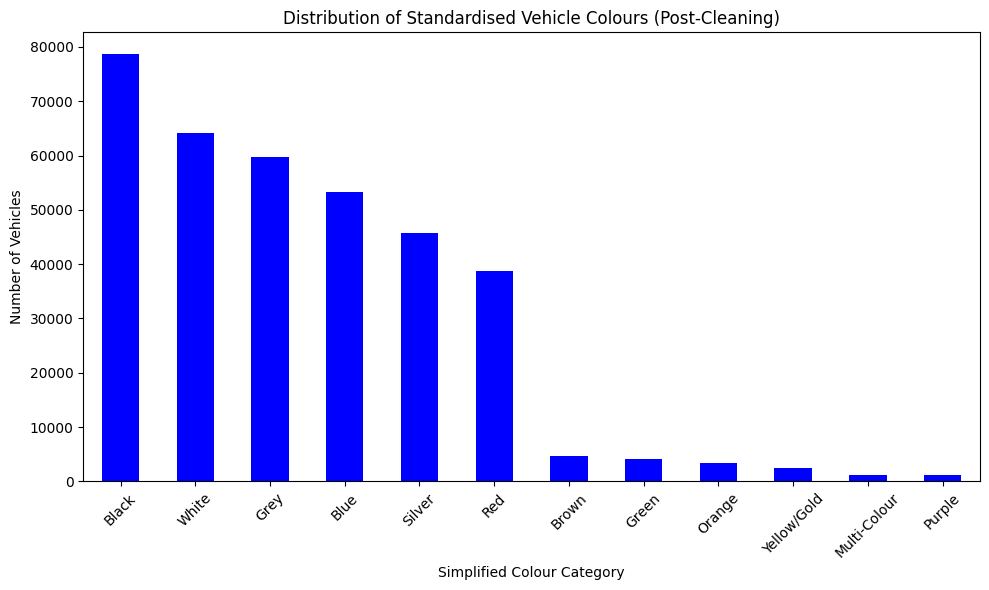

In [105]:
# Visualising the cleaned distribution

# Calculate the counts for new standardised groups
cleaned_counts = df['cleaned_colour'].value_counts()

plt.figure(figsize=(10, 6))
cleaned_counts.plot(kind='bar', color='blue')
plt.title('Distribution of Standardised Vehicle Colours (Post-Cleaning)')
plt.xlabel('Simplified Colour Category')
plt.ylabel('Number of Vehicles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

This is much more interpretable than the first version, and allows for easier grouping, a random person who has never purchased a car before would most likely not know the difference between a maroon and burgundy car.

#2.2 - Brand Categorisation for Feature Engineering
This part aims to categorise cars into certain categories e.g. vintage, luxury, economy + more, for reduced cardinality.

In [106]:
# Identifying High-Cardinality Brands for Categorisation

# List the counts for every individual brand entry in standard_make
brand_counts = df['standard_make'].value_counts()

print("Individual Brand Frequency (Raw Data):")
print("-" * 30)
for brand, count in brand_counts.items():
    print(f"{brand}: {count} cars")

# Print the total number of unique brand categories found
print("-" * 30)
print(f"Total Unique Brand Categories: {len(brand_counts)}")

Individual Brand Frequency (Raw Data):
------------------------------
BMW: 35220 cars
Audi: 31813 cars
Vauxhall: 31595 cars
Volkswagen: 30461 cars
Mercedes-Benz: 29756 cars
Nissan: 18498 cars
Toyota: 16234 cars
Peugeot: 13975 cars
Land Rover: 12737 cars
Kia: 11491 cars
MINI: 10821 cars
SKODA: 10615 cars
Renault: 10533 cars
Hyundai: 10089 cars
Citroen: 9550 cars
Volvo: 9218 cars
Honda: 8755 cars
SEAT: 8111 cars
Fiat: 7183 cars
Jaguar: 6489 cars
Mazda: 5917 cars
Suzuki: 4304 cars
Porsche: 3770 cars
Mitsubishi: 2852 cars
Lexus: 2673 cars
Dacia: 2382 cars
Smart: 1244 cars
Alfa Romeo: 1244 cars
Jeep: 1191 cars
DS AUTOMOBILES: 1188 cars
MG: 941 cars
Subaru: 914 cars
Abarth: 767 cars
Bentley: 710 cars
SsangYong: 535 cars
Chevrolet: 486 cars
Aston Martin: 482 cars
Maserati: 422 cars
Tesla: 352 cars
Saab: 336 cars
Ferrari: 222 cars
Infiniti: 204 cars
Chrysler: 184 cars
Lotus: 111 cars
Rover: 94 cars
Rolls-Royce: 82 cars
Dodge: 73 cars
Daihatsu: 68 cars
McLaren: 54 cars
Lamborghini: 51 cars
Isuz

As we can see, there is 100 car makes, this has an extremely high cardinality, and would be extremely difficult to visualise on a graph, because of this we can categorise them into smaller groups.

In [107]:
# 2.2 Feature Engineering: Refined Brand Categorisation

# Defining a more granular mapping (8 Groups)
# This provides a better balance for identifying group differences, whilst not oversimplifying the groups
brand_mapping = {
    # Ultra-Luxury & Supercars
    'Rolls-Royce': 'Ultra-Luxury', 'Bentley': 'Ultra-Luxury', 'Ferrari': 'Ultra-Luxury',
    'Lamborghini': 'Ultra-Luxury', 'McLaren': 'Ultra-Luxury', 'Aston Martin': 'Ultra-Luxury',

    # High-End Sport (Performance focused)
    'Porsche': 'High-End Sport', 'Lotus': 'High-End Sport', 'Maserati': 'High-End Sport',
    'Alpine': 'High-End Sport',

    # German Premium (The 'Big Three' + similar)
    'BMW': 'Premium', 'Audi': 'Premium', 'Mercedes-Benz': 'Premium',

    # Specialist Premium (Luxury SUVs and Executive)
    'Land Rover': 'Specialist Premium', 'Jaguar': 'Specialist Premium', 'Volvo': 'Specialist Premium',
    'Lexus': 'Specialist Premium', 'Tesla': 'Specialist Premium',

    # Upper Mainstream (Reliable/Popular Volume sellers)
    'Volkswagen': 'Upper Mainstream', 'Toyota': 'Upper Mainstream', 'Honda': 'Upper Mainstream',
    'Mazda': 'Upper Mainstream', 'MINI': 'Upper Mainstream',

    # Mainstream (High volume, mass produced general market)
    'Ford': 'Mainstream', 'Vauxhall': 'Mainstream', 'Nissan': 'Mainstream', 'Peugeot': 'Mainstream',
    'Kia': 'Mainstream', 'Hyundai': 'Mainstream', 'Renault': 'Mainstream', 'SKODA': 'Mainstream',
    'SEAT': 'Mainstream', 'Citroen': 'Mainstream', 'Fiat': 'Mainstream',

    # Budget (Value-focused brands)
    'Dacia': 'Budget', 'MG': 'Budget', 'Suzuki': 'Budget', 'Mitsubishi': 'Budget',
    'Smart': 'Budget', 'SsangYong': 'Budget',

}

# 2. Apply the mapping
df['brand_segment'] = df['standard_make'].map(brand_mapping).fillna('Vintage/Niche')

# 3. List the counts for the new engineered segments
segment_counts = df['brand_segment'].value_counts()

print("Refined Brand Segments Frequency (8 Groups):")
print("-" * 30)
for segment, count in segment_counts.items():
    print(f"{segment}: {count} cars")

# 4. Total count check
print("-" * 30)
print(f"Total Unique Segments: {len(segment_counts)}")

Refined Brand Segments Frequency (8 Groups):
------------------------------
Mainstream: 131640 cars
Premium: 96789 cars
Upper Mainstream: 72188 cars
Specialist Premium: 31469 cars
Budget: 12258 cars
Vintage/Niche: 7103 cars
High-End Sport: 4319 cars
Ultra-Luxury: 1601 cars
------------------------------
Total Unique Segments: 8


/tmp/ipython-input-3704759577.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='brand_segment', y='price', palette='magma')


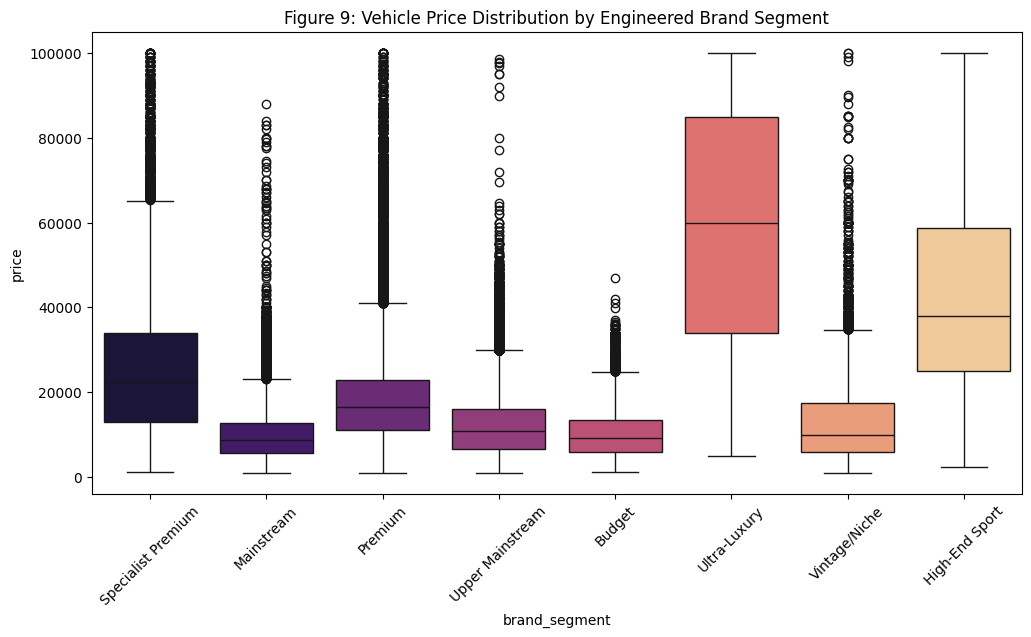

In [108]:
# Visualising the usefulness of the engineered feature
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='brand_segment', y='price', palette='magma')
plt.title('Figure 9: Vehicle Price Distribution by Engineered Brand Segment')
plt.xticks(rotation=45)
plt.show()

# Continued - Visualise Mileage Per Year

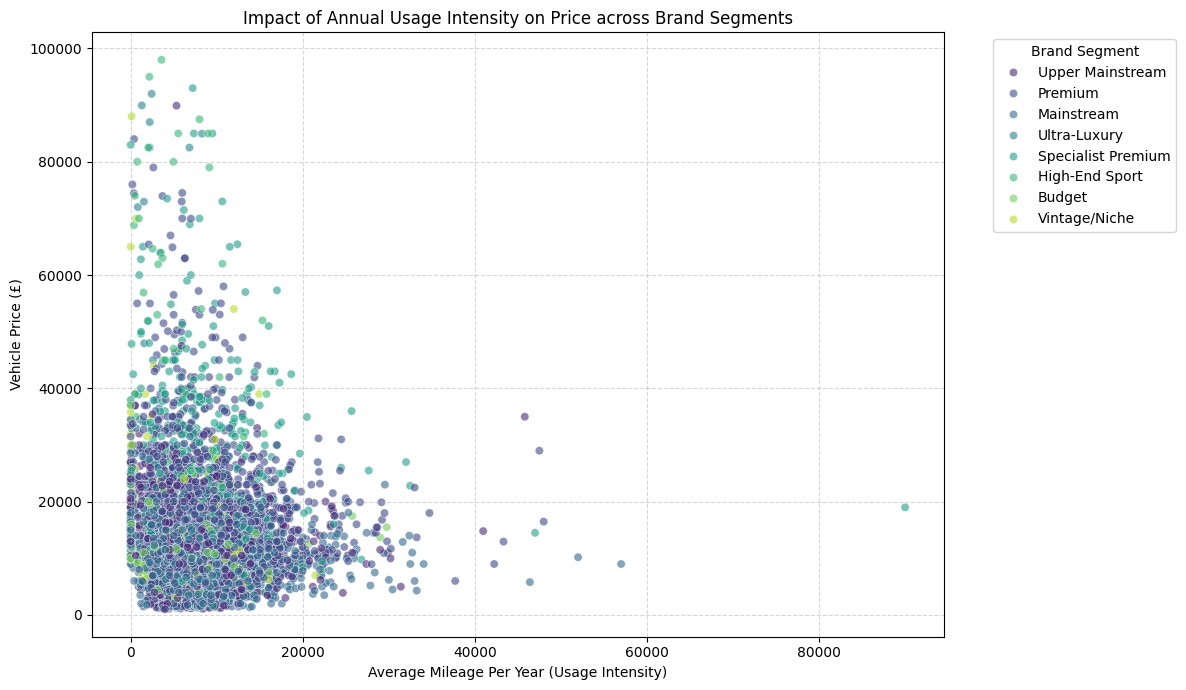

In [109]:
# 2.2 Visualising Engineered Features: Usage Intensity vs Market Segment

# Update the sample to include the new brand segments
df_sample = df.sample(5000, random_state=42).copy()

# Plotting Mileage Per Year vs Price, categorised by Brand Segment

plt.figure(figsize=(12, 7))

# We use a scatter plot to show the relationship between usage and value
sns.scatterplot(
    data=df_sample,
    x='mileage_per_year',
    y='price',
    hue='brand_segment',
    alpha=0.6,
    palette='viridis'
)

# Plot Graph
plt.title('Impact of Annual Usage Intensity on Price across Brand Segments')
plt.xlabel('Average Mileage Per Year (Usage Intensity)')
plt.ylabel('Vehicle Price (£)')
plt.legend(title='Brand Segment', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Analysis done in report

# 2.3 - Subsetting

## 2.3.1 Subsetting of Electric Cars

In [110]:
# 2.3 Subsetting: Creating an Electric Vehicle (EV) Analysis Set

# Creating a row-filtered subset of only Electric vehicles
# Use the cleaned 'fuel_type' column defined in section 2.2.1
electric_subset = df[df['fuel_type'] == 'Electric'].copy()

# Verification of the subset size
print(f"Total Electric Vehicles in subset: {len(electric_subset)}")
print("-" * 30)

# View the first few rows to ensure standard_make is still present - useful in future
display(electric_subset[['standard_make', 'brand_segment', 'price', 'mileage']].head())

# Check which brands are currently offering Electric vehicles in dataset
print("\nElectric Vehicle Distribution by Brand Segment:")
print(electric_subset['brand_segment'].value_counts())

Total Electric Vehicles in subset: 3114
------------------------------


,standard_make,brand_segment,price,mileage
133,Renault,Mainstream,8990,28595.0
268,MG,Budget,20000,1008.0
397,Hyundai,Mainstream,25999,6851.0
445,Nissan,Mainstream,20995,15090.0
476,Nissan,Mainstream,20495,5000.0



Electric Vehicle Distribution by Brand Segment:
brand_segment
Mainstream            1839
Specialist Premium     564
Premium                397
Budget                 175
Upper Mainstream       125
High-End Sport           7
Vintage/Niche            7
Name: count, dtype: int64


## 2.3.1 Feature Selection - Strategic

In [111]:
# List columns for the full dataframe
print("Full Dataframe Columns:")
print(df.columns.tolist())

print("\n" + "-"*30 + "\n")

# List columns for your new Electric subset
print("Electric Subset Columns:")
print(electric_subset.columns.tolist())

Full Dataframe Columns:
['mileage', 'reg_code', 'standard_colour', 'standard_make', 'standard_model', 'vehicle_condition', 'year_of_registration', 'price', 'body_type', 'crossover_car_and_van', 'fuel_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'log_price', 'fuel_group', 'cleaned_colour', 'brand_segment']

------------------------------

Electric Subset Columns:
['mileage', 'reg_code', 'standard_colour', 'standard_make', 'standard_model', 'vehicle_condition', 'year_of_registration', 'price', 'body_type', 'crossover_car_and_van', 'fuel_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'log_price', 'fuel_group', 'cleaned_colour', 'brand_segment']


In [112]:
df.sample()

,mileage,reg_code,standard_colour,standard_make,standard_model,vehicle_condition,year_of_registration,price,body_type,crossover_car_and_van,fuel_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category,log_price,fuel_group,cleaned_colour,brand_segment
80560,31320.0,15,Red,SEAT,Mii,USED,2015,5650,Hatchback,False,Petrol,5,0.180396,6264.0,1,Mid,3.752048,Petrol,Red,Mainstream


In [113]:
# 2.3.2 Subsetting: Strategic Feature Selection

# List of redundant columns identified after feature engineering and EDA
columns_to_remove = [
    'standard_make',         # Replaced by high-quality 'brand_segment' tiers
    'year_of_registration',  # Replaced by 'car_age_2020' and 'age_category'
    'reg_code',              # Simple number with low predictive value for valuation
    'crossover_car_and_van',  # Replaced by refined 'Van Type' compilation
    'standard_colour',        # Replaced by 'cleaned_colour', reduced cardinality
    'fuel_type'              # A column named fuel_group reduces types to 5 from 9

]

# Dropping redundant columns to reduce noise for Association Analysis
# Use .copy() to create a clean, independent dataframe for Section 3
df = df.drop(columns=columns_to_remove)

# Verify the successful reduction of the feature space
print(f"Subsetting Complete: {len(columns_to_remove)} redundant features removed.")
print("-" * 50)
print("Remaining features for Association Analysis:")
print(df.columns.tolist())

Subsetting Complete: 6 redundant features removed.
--------------------------------------------------
Remaining features for Association Analysis:
['mileage', 'standard_model', 'vehicle_condition', 'price', 'body_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'log_price', 'fuel_group', 'cleaned_colour', 'brand_segment']


In [114]:
# Refining the Electric Subset: Feature Selection

# List of redundant columns to remove (same logic as the main dataframe)
cols_to_drop = [
    'standard_make',
    'year_of_registration',
    'reg_code',
    'crossover_car_and_van',
    'standard_colour',
    'fuel_type'
]

# Apply the drop to the electric subset
# Use errors='ignore' just in case a column was already dropped
electric_subset = electric_subset.drop(columns=cols_to_drop, errors='ignore')

# Verification
print("Refined Electric Subset - Final Feature List:")
print("-" * 40)
print(electric_subset.columns.tolist())
print(f"\nRemaining features: {len(electric_subset.columns)}")

Refined Electric Subset - Final Feature List:
----------------------------------------
['mileage', 'standard_model', 'vehicle_condition', 'price', 'body_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'log_price', 'fuel_group', 'cleaned_colour', 'brand_segment']

Remaining features: 14


## 2.3.3 High Mileage Subset

In [115]:
# Exploring High-Mileage Thresholds for Section 2.3.3
# We want to find out which mileage range has the best amount for a subset

thresholds = [80000, 90000, 100000]

print("Market Volume by Mileage Threshold:")
print("-" * 35)

for m in thresholds:
    count = len(df[df['mileage'] > m])
    percentage = (count / len(df)) * 100
    print(f"Cars with > {m:,} miles: {count} ({percentage:.2f}% of total data)")

# Previewing the top of the 90k threshold specifically
print("\n" + "-" * 35)
print("Preview of 90,000+ Mile Records:")
display(df[df['mileage'] > 90000][['standard_model', 'mileage', 'price', 'brand_segment']].head())

Market Volume by Mileage Threshold:
-----------------------------------
Cars with > 80,000 miles: 47447 (13.28% of total data)
Cars with > 90,000 miles: 33379 (9.34% of total data)
Cars with > 100,000 miles: 21655 (6.06% of total data)

-----------------------------------
Preview of 90,000+ Mile Records:


,standard_model,mileage,price,brand_segment
1,XF,108230.0,7000,Specialist Premium
7,Range Rover,99000.0,24475,Specialist Premium
8,S Class,111236.0,6995,Premium
24,Astra GTC,98000.0,3795,Mainstream
32,Octavia,180000.0,3989,Mainstream


As we can see, 90k is the sweet spot, as it accounts for nearly 10% of data, whilst containing a wide range of brand_segments, prices and models.

In [116]:
# 2.3.3 Subsetting: High-Mileage 'Workhorse' Market

# Creating the subset with the 90,000 mile boundary
workhorse_subset = df[df['mileage'] > 90000].copy()

# List of redundant columns to remove (Feature Selection Continued)
cols_to_drop = [
    'standard_make', 'year_of_registration', 'reg_code',
    'crossover_car_and_van', 'standard_colour', 'fuel_type'
]

# Apply column removal
workhorse_subset = workhorse_subset.drop(columns=cols_to_drop, errors='ignore')

print(f"Workhorse Subset Created: {len(workhorse_subset)} records.")
print(f"Remaining Features: {workhorse_subset.columns.tolist()}")

Workhorse Subset Created: 33379 records.
Remaining Features: ['mileage', 'standard_model', 'vehicle_condition', 'price', 'body_type', 'car_age_2020', 'price_per_mile', 'mileage_per_year', 'is_used', 'age_category', 'log_price', 'fuel_group', 'cleaned_colour', 'brand_segment']


In [117]:
# Verifying the Workhorse Subset (90k+ Miles)

# 10 random samples to inspect the data structure
workhorse_sample = workhorse_subset.sample(10)

# Displaying the sample to confirm feature selection and row filtering
print(f"Random Sample of 10 records from the {len(workhorse_subset)} high-mileage entries:")
print("-" * 80)
display(workhorse_sample)

# Double-check: Ensure no mileage is below 90,000
print("-" * 80)
print(f"Minimum mileage in subset: {workhorse_subset['mileage'].min():,}")
print(f"Columns remaining: {len(workhorse_subset.columns)}")

Random Sample of 10 records from the 33379 high-mileage entries:
--------------------------------------------------------------------------------


,mileage,standard_model,vehicle_condition,price,body_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category,log_price,fuel_group,cleaned_colour,brand_segment
127807,97000.0,Hatch,USED,2153,Hatchback,11,0.022196,8818.181818,1,Old,3.333044,Diesel,White,Upper Mainstream
311234,105000.0,E Class,USED,6990,Saloon,10,0.066571,10500.000000,1,Old,3.844477,Diesel,Black,Premium
279147,108000.0,Astra,USED,1695,Estate,12,0.015694,9000.000000,1,Old,3.229170,Petrol,Silver,Mainstream
245875,96446.0,2008,USED,6495,SUV,5,0.067343,19289.200000,1,Mid,3.812579,Diesel,Grey,Mainstream
271083,100000.0,Megane,USED,4450,Hatchback,12,0.044500,8333.333333,1,Old,3.648360,Petrol,Silver,Mainstream
105673,128800.0,C Class,USED,12995,Saloon,4,0.100893,32200.000000,1,Mid,4.113776,Hybrid,Black,Premium
231464,94823.0,A3,USED,7500,Hatchback,6,0.079095,15803.833333,1,Mid,3.875061,Diesel,White,Premium
162984,104000.0,A3,USED,8995,Hatchback,4,0.086490,26000.000000,1,Mid,3.954001,Diesel,Grey,Premium
145575,129553.0,Tiguan,USED,4125,SUV,12,0.031840,10796.083333,1,Old,3.615424,Diesel,Black,Upper Mainstream
337759,99090.0,Juke,USED,3995,SUV,9,0.040317,11010.000000,1,Old,3.601517,Petrol,Blue,Mainstream


--------------------------------------------------------------------------------
Minimum mileage in subset: 90,001.0
Columns remaining: 14


# Section 3 - Analysis


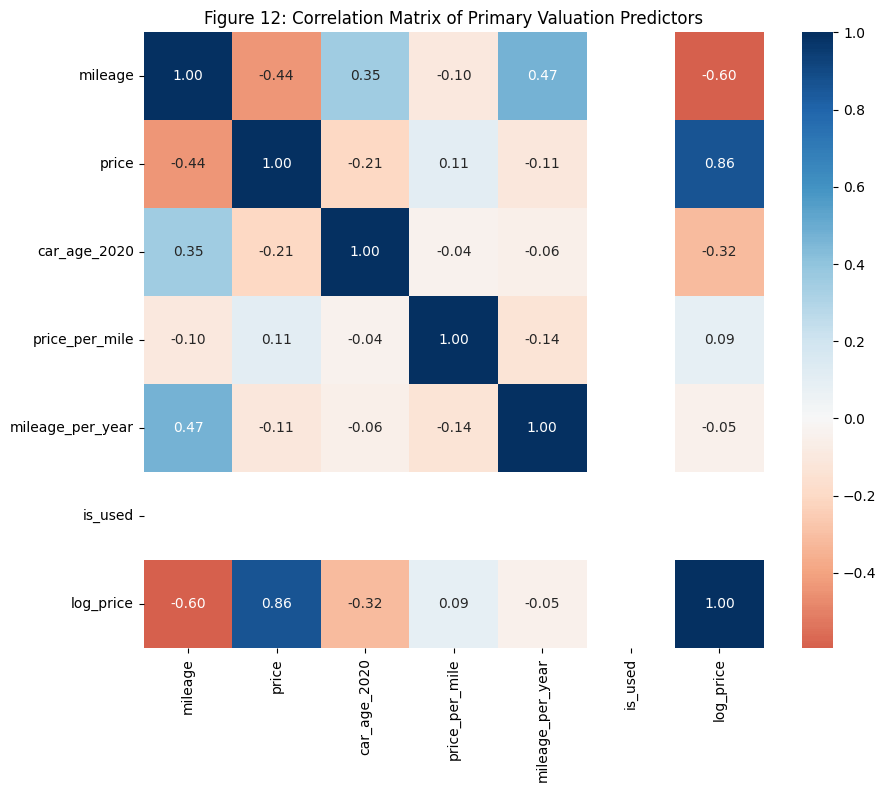

In [118]:
# 1. Identify final numerical columns (Target + Engineered Features)
# We exclude columns already dropped or those that are categorical/strings
final_numerical = df.select_dtypes(include=['number']).columns

# 2. Calculate Correlation matrix
corr_matrix = df[final_numerical].corr()

# 3. Plotting the Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='RdBu', center=0, fmt=".2f")

plt.title('Figure 12: Correlation Matrix of Primary Valuation Predictors')
plt.show()



1.   Mileage vs Price (-0.44) has a correlation with
     Mileage vs log price (-0.60), proving the relationship isn't just a straight line.  

2.   Successful Feature Engineering of car_age_2020
     The raw registration was backwards as it suggested higher year = lower mileage, the engineered car_age_2020 fixed this.



How Does Vehicle Mileage Impact market value, and does the rate of depreciation remain constant or accelerate over the vehicle's life cycle?

Justification: correlaton between -0.44 for mileage v price and -0.60 for mileage v log price.

## Graph 1: The "Real World" View (Mileage vs. Price)

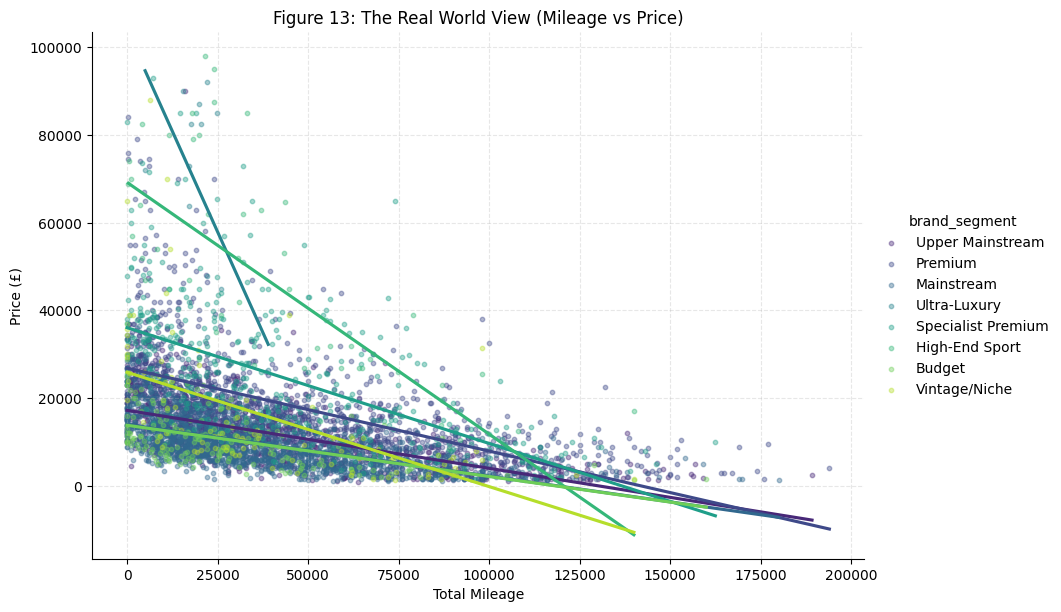

In [119]:
# Figure 13: The Real World View (Mileage vs Price)
# Market Positioning and Depreciation by Brand Tier
sns.lmplot(data=df_sample, x='mileage', y='price', hue='brand_segment',
           palette='viridis', height=6, aspect=1.5,
           scatter_kws={'alpha':0.4, 's':10}, ci=None)

plt.title('Figure 13: The Real World View (Mileage vs Price)')
plt.xlabel('Total Mileage')
plt.ylabel('Price (£)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## Analysis



*   Market Segmentation: Showing how the prices are tiered, Luxury starts much higher.

*   Spread: The points are more spread out at higher prices (lower mileage) and more compressed at lower prices (bottom left of graph).

*   Curved Relationship: Even with the lines, the scatter points typically curve.

*   Slopes: Steeper Lines for premium brands mean higher depreciation per mile.



## Graph 2: The "Mathematical" View (Mileage vs. Log Price)

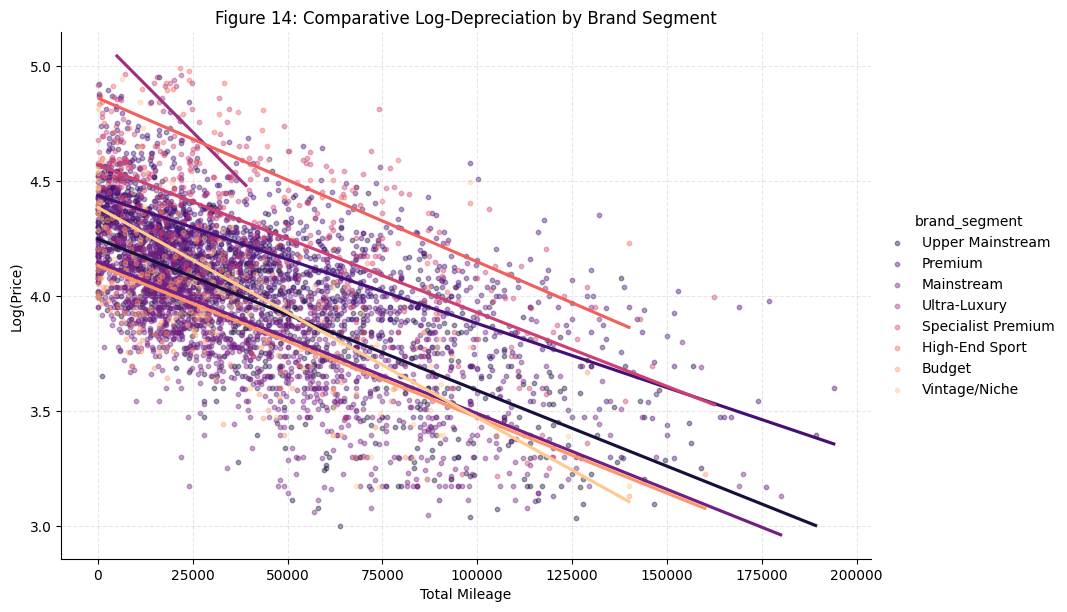

In [120]:
# Figure 14: Standardised Percentage Depreciation by Brand Tier
sns.lmplot(data=df_sample, x='mileage', y='log_price', hue='brand_segment',
           palette='magma', height=6, aspect=1.5,
           scatter_kws={'alpha':0.4, 's':10}, ci=None)

plt.title('Figure 14: Comparative Log-Depreciation by Brand Segment')
plt.xlabel('Total Mileage')
plt.ylabel('Log(Price)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

## Analysis

*   Linear: Relationships have much straighter lines than Figure 13.

*   Spread: Spread of points is more uniform along the line.

*   Slopes: When using log price, parallel lines indicate that the cars are losing value at a similar rate regardless of starting price.

*   Justified: Plot shows why log price is superior target variable for regression.



# 3.2 - Price by Fuel Group

Since I used Brand Segment for the Q-Q section (the colored dots), I am going to use two different categorical variables for 3.2 to show the spread of the data. I will use fuel_group and age_category to show how different groups affect the price distribution.

## Example 1: The "Alternative Fuel Premium" (Price by Fuel Group)
This aims to show how modern fuels (Electric/Hybrid) carry a price premium

/tmp/ipython-input-1355196956.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='fuel_group', y='price', palette='Set2')


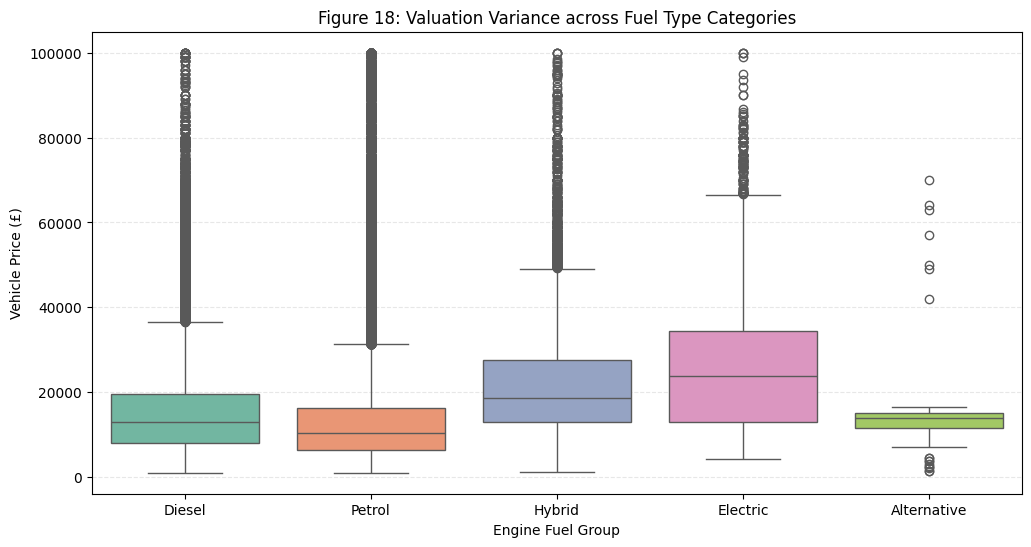

In [121]:
# Section 3.2: Quantitative-Categorical Analysis (Example 1)

plt.figure(figsize=(12, 6))

# Boxplot showing price distribution across Fuel Groups
# This allows me to see the Median, IQRs, and Outliers clearly
sns.boxplot(data=df, x='fuel_group', y='price', palette='Set2')

plt.title('Figure 18: Valuation Variance across Fuel Type Categories')
plt.xlabel('Engine Fuel Group')
plt.ylabel('Vehicle Price (£)')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

Analysis:

Outliers: The dots above the whiskers show "extreme" cases, like luxury petrol cars that cost much more than the average. There is a much lower amount of dots on the electric group, with petrol and diesel having huge amounts.

Insight: It reveals the "newer technologies" (Electric/Hybrid) were more expensive in 2020, as expected.



/tmp/ipython-input-3600523453.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='age_category', y='log_price', palette='coolwarm')


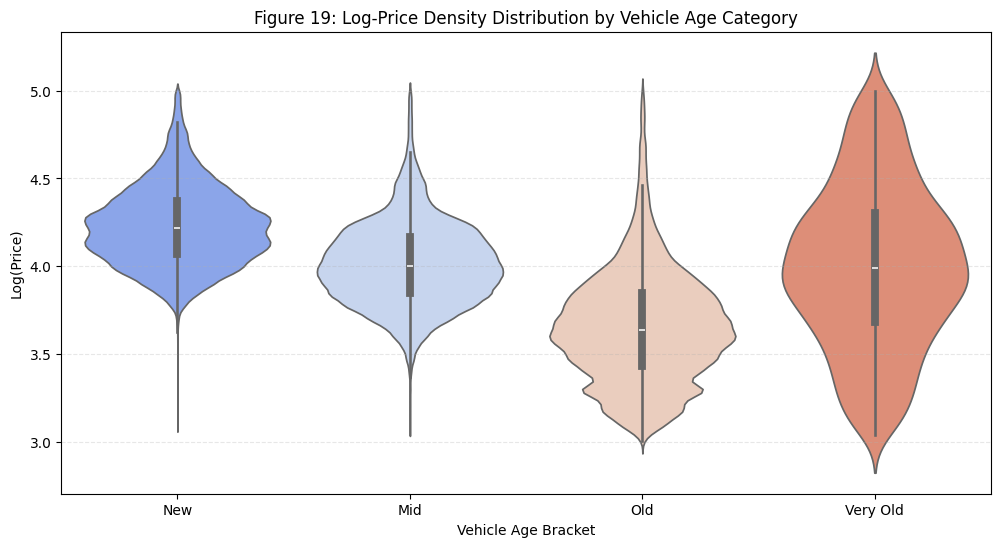

In [122]:
# Section 3.2: Quantitative-Categorical Analysis (Example 2)

plt.figure(figsize=(12, 6))

# Violin plot provides a "Nuanced Exploration" of density and distribution
# It shows where most of the cars are priced within each age bracket
sns.violinplot(data=df, x='age_category', y='log_price', palette='coolwarm')

plt.title('Figure 19: Log-Price Density Distribution by Vehicle Age Category')
plt.xlabel('Vehicle Age Bracket')
plt.ylabel('Log(Price)')
plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

Analysis:

New Cars: Likely have a distribution concentrated at higher log-prices.

Old Cars: The "fat" part of the violin is much lower down the Y-axis.

Comparison: It shows that as cars age, not only does the median price drop, but the distribution changes. The distribution of older cars is often more concentrated around a lower "scrap value" or budget price point, whereas newer cars have a broader distribution depending on the brand/spec.

Insight: Using log_price makes the comparison fairer and more readable across categories that have huge price differences.

## 3.3 Brand Segment vs Fuel Type

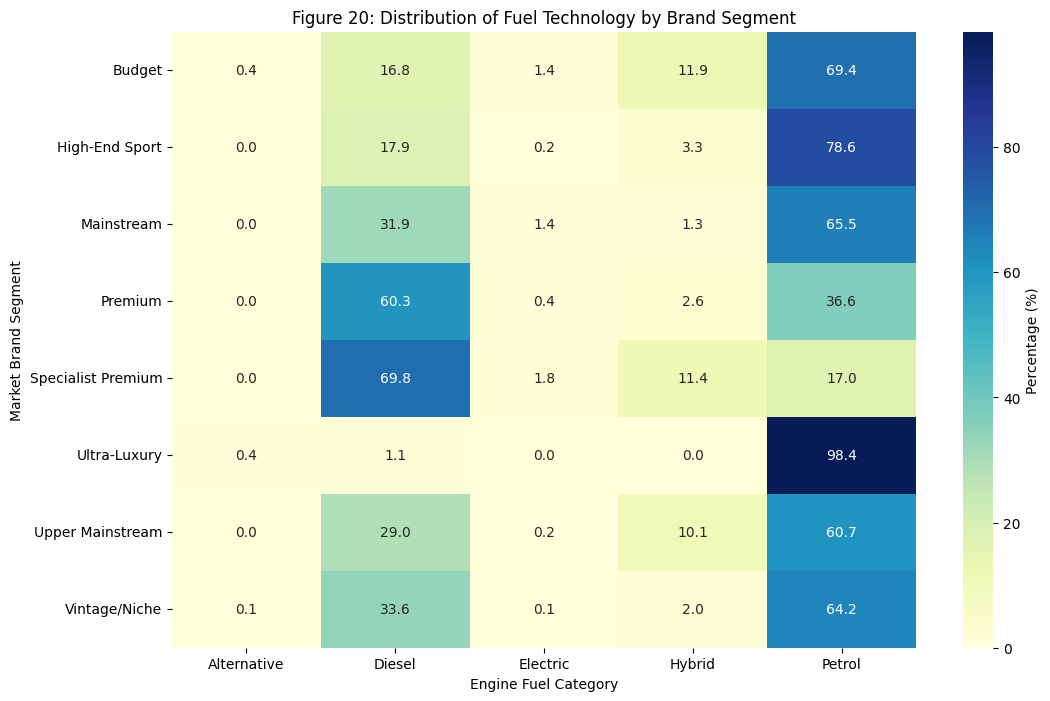

In [123]:
# Section 3.3: Categorical-Categorical Analysis

# Create a cross-tabulation of Brand Segment and Fuel Group
# Use 'normalize=index' to see the percentage breakdown per brand tier
ct = pd.crosstab(df['brand_segment'], df['fuel_group'], normalize='index') * 100

plt.figure(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Percentage (%)'})

plt.title('Figure 20: Distribution of Fuel Technology by Brand Segment')
plt.xlabel('Engine Fuel Category')
plt.ylabel('Market Brand Segment')
plt.show()

<Figure size 1200x600 with 0 Axes>

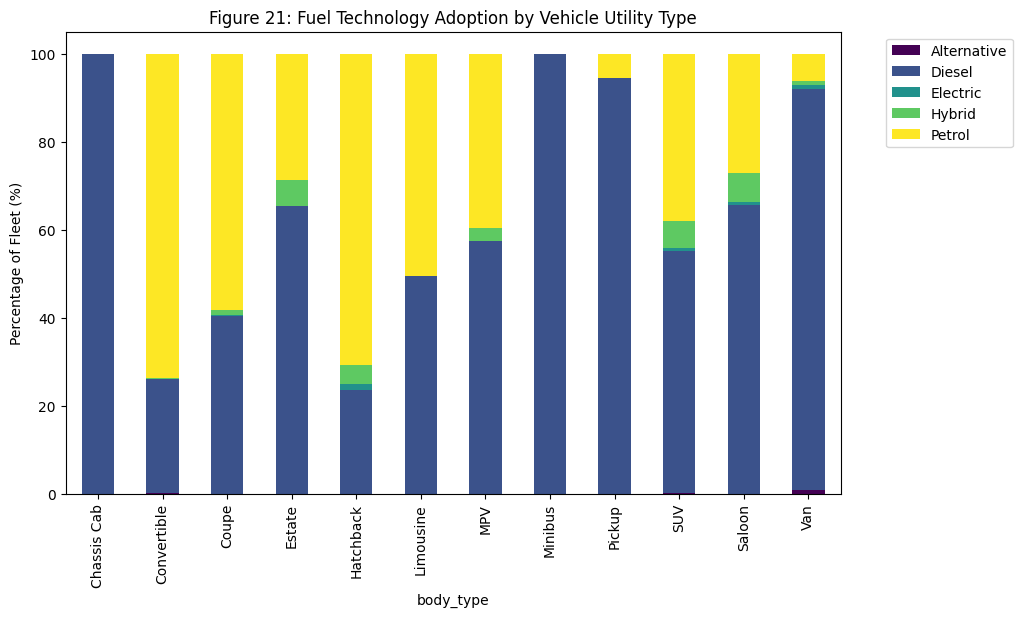

In [124]:
# Create cross-tab for Utility Type vs Fuel
ct_van = pd.crosstab(df['body_type'], df['fuel_group'], normalize='index') * 100

plt.figure(figsize=(12, 6))
ct_van.plot(kind='bar', stacked=True, colormap='viridis', figsize=(10,6))
plt.title('Figure 21: Fuel Technology Adoption by Vehicle Utility Type')
plt.ylabel('Percentage of Fleet (%)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [125]:
df.describe(include='all').T
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 357367 entries, 1 to 402004
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   mileage            357367 non-null  float64 
 1   standard_model     357367 non-null  object  
 2   vehicle_condition  357367 non-null  object  
 3   price              357367 non-null  int64   
 4   body_type          357367 non-null  object  
 5   car_age_2020       357367 non-null  int64   
 6   price_per_mile     357367 non-null  float64 
 7   mileage_per_year   357367 non-null  float64 
 8   is_used            357367 non-null  int64   
 9   age_category       357142 non-null  category
 10  log_price          357367 non-null  float64 
 11  fuel_group         357367 non-null  object  
 12  cleaned_colour     357367 non-null  object  
 13  brand_segment      357367 non-null  object  
dtypes: category(1), float64(4), int64(3), object(6)
memory usage: 38.5+ MB


In [126]:
df = df.reset_index(drop=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357367 entries, 0 to 357366
Data columns (total 14 columns):
 #   Column             Non-Null Count   Dtype   
---  ------             --------------   -----   
 0   mileage            357367 non-null  float64 
 1   standard_model     357367 non-null  object  
 2   vehicle_condition  357367 non-null  object  
 3   price              357367 non-null  int64   
 4   body_type          357367 non-null  object  
 5   car_age_2020       357367 non-null  int64   
 6   price_per_mile     357367 non-null  float64 
 7   mileage_per_year   357367 non-null  float64 
 8   is_used            357367 non-null  int64   
 9   age_category       357142 non-null  category
 10  log_price          357367 non-null  float64 
 11  fuel_group         357367 non-null  object  
 12  cleaned_colour     357367 non-null  object  
 13  brand_segment      357367 non-null  object  
dtypes: category(1), float64(4), int64(3), object(6)
memory usage: 35.8+ MB


In [128]:
df.sample(20)

,mileage,standard_model,vehicle_condition,price,body_type,car_age_2020,price_per_mile,mileage_per_year,is_used,age_category,log_price,fuel_group,cleaned_colour,brand_segment
342876,3000.0,Hatch,USED,24990,Hatchback,1,8.330000,3000.000000,1,New,4.397766,Petrol,Red,Upper Mainstream
312673,47808.0,E Class,USED,21990,Saloon,4,0.459965,11952.000000,1,Mid,4.342225,Diesel,White,Premium
311776,99740.0,A4 Avant,USED,13295,Estate,3,0.133297,33246.666667,1,New,4.123688,Diesel,Black,Premium
203188,45864.0,Ibiza,USED,7750,Hatchback,3,0.168978,15288.000000,1,New,3.889302,Petrol,White,Mainstream
165818,16670.0,Passat,USED,15000,Saloon,1,0.899820,16670.000000,1,New,4.176091,Petrol,Black,Upper Mainstream
127660,48000.0,Freelander 2,USED,13500,SUV,7,0.281250,6857.142857,1,Mid,4.130334,Diesel,Black,Specialist Premium
175173,71000.0,Meriva,USED,3495,MPV,9,0.049225,7888.888889,1,Old,3.543447,Petrol,Silver,Mainstream
339513,42322.0,Range Rover Evoque,USED,17700,SUV,6,0.418222,7053.666667,1,Mid,4.247973,Diesel,White,Specialist Premium
252191,85000.0,Corsa,USED,2000,Hatchback,8,0.023529,10625.000000,1,Old,3.301030,Petrol,Orange,Mainstream
89430,108956.0,A3,USED,9990,Saloon,4,0.091688,27239.000000,1,Mid,3.999565,Petrol,Black,Premium
